In [1]:
# Path to the rba-dataset.csv.
CSV_PATH = "data/raw/rba-dataset.csv"

In [2]:
# Tree building changed between scikit-learn versions; pinning it keeps the forests identical on any machine.
%pip install -q --disable-pip-version-check scikit-learn==1.9.1

Note: you may need to restart the kernel to use updated packages.


In [3]:
import math
import os
import platform
import subprocess
import time
from collections import Counter, deque
from dataclasses import dataclass, field
from datetime import datetime, timedelta
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.ensemble import IsolationForest, RandomForestClassifier
from sklearn.metrics import roc_auc_score, roc_curve

# Any fixed number works here; fixing it makes every random step (sampling, forests) repeatable.
SEED = 42
WORK = Path("work")  # cleaned Parquet files go here
WORK.mkdir(exist_ok=True)
FIGURES = Path("figures")  # the figures used in the report, at 300 dpi
FIGURES.mkdir(exist_ok=True)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

In [4]:
# The machine and library versions of this run. The speed results at the end depend on them.
def cpu_name():
    try:
        if platform.system() == "Darwin":
            return subprocess.run(["sysctl", "-n", "machdep.cpu.brand_string"], capture_output=True, text=True).stdout.strip()
        with open("/proc/cpuinfo") as info:
            return next(line.split(":", 1)[1].strip() for line in info if line.startswith("model name"))
    except (OSError, StopIteration):
        return platform.processor() or "unknown"


ENVIRONMENT = {"run on": datetime.now().strftime("%Y-%m-%d %H:%M"), "system": platform.platform(), "processor": cpu_name(),
               "cores": os.cpu_count(), "memory (GB)": round(os.sysconf("SC_PAGE_SIZE") * os.sysconf("SC_PHYS_PAGES") / 2**30, 1),
               "python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
               "duckdb": duckdb.__version__, "scikit-learn": sklearn.__version__, "matplotlib": plt.matplotlib.__version__}
pd.Series(ENVIRONMENT).to_frame("this run")

,this run
run on,2026-11-08 12:26
system,macOS-27.2-arm64-arm-64bit
processor,Apple M5
cores,10
memory (GB),16.0
python,3.12.11
numpy,2.5.3
pandas,3.0.6
duckdb,1.5.6
scikit-learn,1.9.1


In [5]:
# 1. First look at the raw file. It is about 9 GB, so DuckDB reads it from disk instead of loading it into pandas.
# Its memory is capped so this also fits on a laptop or free Colab.
con = duckdb.connect()
con.execute("SET memory_limit = '6GB'")
con.execute(f"SET temp_directory = '{WORK / 'duckdb_tmp'}'")
print(f"{Path(CSV_PATH).stat().st_size / 1e9:.1f} GB")
con.sql(f"DESCRIBE SELECT * FROM read_csv('{CSV_PATH}')").df()[["column_name", "column_type"]]

9.1 GB


,column_name,column_type
0,index,BIGINT
1,Login Timestamp,TIMESTAMP
2,User ID,BIGINT
3,Round-Trip Time [ms],DOUBLE
4,IP Address,VARCHAR
5,Country,VARCHAR
6,Region,VARCHAR
7,City,VARCHAR
8,ASN,BIGINT
9,User Agent String,VARCHAR


In [6]:
# A few rows as they are in the file.
con.sql(f"SELECT * FROM read_csv('{CSV_PATH}') LIMIT 5").df()

,index,Login Timestamp,User ID,Round-Trip Time [ms],IP Address,Country,Region,City,ASN,User Agent String,Browser Name and Version,OS Name and Version,Device Type,Login Successful,Is Attack IP,Is Account Takeover
0,0,2020-02-03 12:43:30.772,-4324475583306591935,NaN,10.0.65.171,NO,-,-,29695,Mozilla/5.0 (iPhone; CPU iPhone OS 13_4 like ...,Firefox 20.0.0.1618,iOS 13.4,mobile,False,False,False
1,1,2020-02-03 12:43:43.549,-4324475583306591935,NaN,194.87.207.6,AU,-,-,60117,Mozilla/5.0 (Linux; Android 4.1; Galaxy Nexus...,Chrome Mobile 46.0.2490,Android 4.1,mobile,False,False,False
2,2,2020-02-03 12:43:55.873,-3284137479262433373,NaN,81.167.144.58,NO,Vestland,Urangsvag,29695,Mozilla/5.0 (iPad; CPU OS 7_1 like Mac OS X) ...,Android 2.3.3.2672,iOS 7.1,mobile,True,False,False
3,3,2020-02-03 12:43:56.180,-4324475583306591935,NaN,170.39.78.152,US,-,-,393398,Mozilla/5.0 (Linux; Android 4.1; Galaxy Nexus...,Chrome Mobile WebView 85.0.4183,Android 4.1,mobile,False,False,False
4,4,2020-02-03 12:43:59.396,-4618854071942621186,NaN,10.0.0.47,US,Virginia,Ashburn,398986,Mozilla/5.0 (Linux; U; Android 2.2) Build/NMA...,Chrome Mobile WebView 85.0.4183,Android 2.2,mobile,False,True,False


In [7]:
# Missing and blank values in the first 200,000 rows: DuckDB already reads empty fields as missing.
head = con.sql(f"SELECT * FROM read_csv('{CSV_PATH}') LIMIT 200000").df()
pd.DataFrame({"missing": head.isna().sum(), "blank_text": (head == "").sum(), "example": head.iloc[0]})

,missing,blank_text,example
index,0,0,0
Login Timestamp,0,0,2020-02-03 12:43:30.772000
User ID,0,0,-4324475583306591935
Round-Trip Time [ms],191143,0,NaN
IP Address,0,0,10.0.65.171
Country,0,0,NO
Region,145,0,-
City,71,0,-
ASN,0,0,29695
User Agent String,0,0,Mozilla/5.0 (iPhone; CPU iPhone OS 13_4 like ...


In [8]:
# 2. Cleaning: short column names, blank text turned into missing (to be safe), proper types for time and true/false.
# Values are never changed and no rows are dropped. Written once to Parquet so later steps are fast.
COLUMNS = {"index": "row_id", "Login Timestamp": "timestamp", "User ID": "user_id", "Round-Trip Time [ms]": "rtt_ms",
           "IP Address": "ip", "Country": "country", "Region": "region", "City": "city", "ASN": "asn",
           "User Agent String": "user_agent", "Browser Name and Version": "browser", "OS Name and Version": "os",
           "Device Type": "device_type", "Login Successful": "success", "Is Attack IP": "is_attack_ip",
           "Is Account Takeover": "is_ato"}
TEXT = {"ip", "country", "region", "city", "user_agent", "browser", "os", "device_type"}
TYPES = {"timestamp": "TIMESTAMP", "rtt_ms": "DOUBLE", "success": "BOOLEAN", "is_attack_ip": "BOOLEAN", "is_ato": "BOOLEAN"}
select = [f'''NULLIF("{old}", '') AS {new}''' if new in TEXT else f'''CAST("{old}" AS {TYPES.get(new, 'BIGINT')}) AS {new}'''
          for old, new in COLUMNS.items()]

FULL = WORK / "rba-full.parquet"
if not FULL.exists():  # takes a few minutes on Colab
    con.execute(f"COPY (SELECT {', '.join(select)} FROM read_csv('{CSV_PATH}')) TO '{FULL}' (FORMAT parquet, COMPRESSION zstd)")
con.sql(f"DESCRIBE SELECT * FROM '{FULL}'").df()[["column_name", "column_type"]]

,column_name,column_type
0,row_id,BIGINT
1,timestamp,TIMESTAMP
2,user_id,BIGINT
3,rtt_ms,DOUBLE
4,ip,VARCHAR
5,country,VARCHAR
6,region,VARCHAR
7,city,VARCHAR
8,asn,BIGINT
9,user_agent,VARCHAR


In [9]:
# Size and time span. Row ids must be unique, since they are used to keep a stable order later.
con.sql(f"""
    SELECT COUNT(*) AS sign_ins, COUNT(DISTINCT row_id) AS unique_row_ids, COUNT(DISTINCT user_id) AS users,
           MIN(timestamp) AS first, MAX(timestamp) AS last
    FROM '{FULL}'""").df().T

,0
sign_ins,31269264
unique_row_ids,31269264
users,4304857
first,2020-02-03 12:43:30.772000
last,2021-02-28 23:59:58.756000


In [10]:
# Duplicates: the same user at the same moment from the same IP and browser.
con.sql(f"""
    SELECT COUNT(*) AS duplicated_groups FROM (
        SELECT user_id, timestamp, ip, user_agent, COUNT(*) AS n FROM '{FULL}' GROUP BY ALL HAVING n > 1)""").df()

,duplicated_groups
0,0


In [11]:
# Share of missing values per column. Round-trip time is missing almost everywhere,
# so it can only be used with a "missing" flag next to it.
missing = con.sql(f"SELECT {', '.join(f'AVG(({c} IS NULL)::INT) AS {c}' for c in COLUMNS.values())} FROM '{FULL}'").df().T
missing.columns = ["missing_share"]
missing.round(4)

,missing_share
row_id,0.0000
timestamp,0.0000
user_id,0.0000
rtt_ms,0.9592
ip,0.0000
country,0.0000
region,0.0015
city,0.0003
asn,0.0000
user_agent,0.0000


In [12]:
# Region and city are a "-" placeholder in almost half the rows, so they are not used. Device type has "unknown"
# and a few missing values; those are kept as they are (they still describe the sign-in).
print(con.sql(f"SELECT AVG((region = '-')::INT) AS region_dash, AVG((city = '-')::INT) AS city_dash FROM '{FULL}'").df())
con.sql(f"SELECT device_type, COUNT(*) AS n FROM '{FULL}' GROUP BY ALL ORDER BY n DESC").df()

   region_dash  city_dash
0     0.448832   0.444794


,device_type,n
0,mobile,19642650
1,desktop,7934515
2,bot,2027834
3,unknown,867371
4,tablet,795368
5,NaN,1526


In [13]:
# Odd values: private 10.x IPs and network numbers (ASN) above 500,000. The dataset's authors say some were made up
# during synthesis without affecting risk scoring. They are only compared for equality here, so they stay.
con.sql(f"""
    SELECT SUM((ip LIKE '10.%')::INT) AS private_10_ips, SUM((asn >= 500000)::INT) AS asn_over_500k,
           COUNT(*) AS sign_ins
    FROM '{FULL}'""").df()

,private_10_ips,asn_over_500k,sign_ins
0,7291335.0,1457824.0,31269264


In [14]:
# The classes: normal sign-ins (with the right or wrong password), sign-ins from known attacker IPs,
# and confirmed account takeovers.
con.sql(f"""
    SELECT is_attack_ip, is_ato, success, COUNT(*) AS sign_ins
    FROM '{FULL}' GROUP BY ALL ORDER BY sign_ins DESC""").df()

,is_attack_ip,is_ato,success,sign_ins
0,False,False,False,16435336
1,False,False,True,11736887
2,True,False,False,2292485
3,True,False,True,804415
4,True,True,True,76
5,False,True,True,64
6,True,True,False,1


In [15]:
# Sign-ins per user are extremely skewed: half the users have 2 or fewer, while one account alone has 14 million.
# So samples are drawn by user, never by row.
per_user = con.sql(f"SELECT user_id, COUNT(*) AS n FROM '{FULL}' GROUP BY user_id").df()["n"]
print(per_user.describe(percentiles=[0.5, 0.9, 0.99]).round(1).to_string())

count     4304857.0
mean            7.3
std          6760.2
min             1.0
50%             2.0
90%             9.0
99%            28.0
max      14025899.0


In [16]:
# Confirmed takeovers are very rare, and all happen between February and November 2020.
con.sql(f"""
    SELECT COUNT(*) AS takeovers, COUNT(DISTINCT user_id) AS users, MIN(timestamp) AS first, MAX(timestamp) AS last
    FROM '{FULL}' WHERE is_ato""").df()

,takeovers,users,first,last
0,141,138,2020-02-04 13:45:50.280,2020-11-23 23:04:43.278


In [17]:
# 3. Sampling. Every sign-in must be replayed one by one in time order (features depend on the user's past),
# which is too slow for 31 million rows in Python. So we sample users and keep each one's full history.

# Results are reported by how many earlier sign-ins the user had. Since most users have few, the buckets
# roughly double in width.
BUCKETS = [(0, 0), (1, 2), (3, 5), (6, 10), (11, 20), (21, None)]


def bucket_label(low, high):
    return f"{low}+" if high is None else (str(low) if low == high else f"{low}-{high}")

In [18]:
# How many users? For a few sample sizes, count the real attacker sign-ins in the last 20% of time (the future
# test period) per history bucket. A rate measured on n cases is only accurate to about ±1/sqrt(n).
all_ids = con.execute(f"SELECT DISTINCT user_id FROM '{FULL}' ORDER BY user_id").fetchnumpy()["user_id"]


def attack_cases(n_users):
    ids = np.random.default_rng(SEED).choice(all_ids, size=n_users, replace=False)
    con.register("candidate_ids", pd.DataFrame({"user_id": ids}))
    return con.sql(f"""
        WITH s AS (SELECT user_id, timestamp, row_id, is_attack_ip, NOT is_attack_ip AND NOT is_ato AND success AS normal
                   FROM '{FULL}' WHERE user_id IN (SELECT user_id FROM candidate_ids)),
             c AS (SELECT *, COALESCE(SUM(normal::INT) OVER (PARTITION BY user_id ORDER BY timestamp, row_id
                                      ROWS BETWEEN UNBOUNDED PRECEDING AND 1 PRECEDING), 0) AS earlier,
                          timestamp >= (SELECT quantile_disc(timestamp, 0.8) FROM s) AS last_20pct FROM s)
        SELECT CASE WHEN earlier = 0 THEN '0' WHEN earlier <= 2 THEN '1-2' WHEN earlier <= 5 THEN '3-5'
                    WHEN earlier <= 10 THEN '6-10' WHEN earlier <= 20 THEN '11-20' ELSE '21+' END AS bucket,
               COUNT(*) AS attacks
        FROM c WHERE is_attack_ip AND last_20pct GROUP BY bucket""").df().set_index("bucket")["attacks"]


cases = pd.DataFrame({n: attack_cases(n) for n in (100_000, 200_000, 300_000)}).loc[[bucket_label(*b) for b in BUCKETS]]
print(cases)
print("\n±1/sqrt(n) for the smallest bucket:", (1 / np.sqrt(cases.min())).round(3).to_dict())

        100000  200000  300000
bucket                        
0         6201   12426   18345
1-2       1379    2749    4100
3-5        487     983    1550
6-10       243     458     735
11-20      117     194     365
21+         84     266     322

±1/sqrt(n) for the smallest bucket: {100000: 0.109, 200000: 0.072, 300000: 0.056}


In [19]:
# With 300,000 users even the smallest bucket has 300+ real attacks (about ±6 points instead of ±11 with 100,000),
# and the ~1.2 million sign-ins are still quick to replay. So 300,000 users it is.
SAMPLE_USERS = 300_000

# Confirmed takeovers are so rare that a random sample of that size catches only a handful of those users.
ato_ids = con.execute(f"SELECT DISTINCT user_id FROM '{FULL}' WHERE is_ato").fetchnumpy()["user_id"]
sampled = np.random.default_rng(SEED).choice(all_ids, size=SAMPLE_USERS, replace=False)
print("users with a takeover:", len(ato_ids), "| in the random sample:", len(np.intersect1d(sampled, ato_ids)))

users with a takeover: 138 | in the random sample: 6


In [20]:
# So the sample is the 300,000 random users plus every user with a takeover, which makes a takeover case study possible.
user_ids = np.union1d(sampled, ato_ids)
con.register("sampled_ids", pd.DataFrame({"user_id": user_ids}))
con.execute(f"CREATE OR REPLACE TABLE sample AS SELECT * FROM '{FULL}' WHERE user_id IN (SELECT user_id FROM sampled_ids)")
print(f"{len(user_ids):,} users, {con.sql('SELECT COUNT(*) FROM sample').fetchone()[0]:,} sign-ins")

300,132 users, 1,193,036 sign-ins


largest gap: 0.13 points


,sign_ins_per_user,sample_pct,full_pct
0,1,39.80,39.67
1,2,19.04,19.06
2,3-5,22.88,22.91
3,6-10,10.98,11.09
4,11-20,5.25,5.23
5,21-50,1.79,1.76
6,51-100,0.19,0.21
7,101+,0.07,0.07


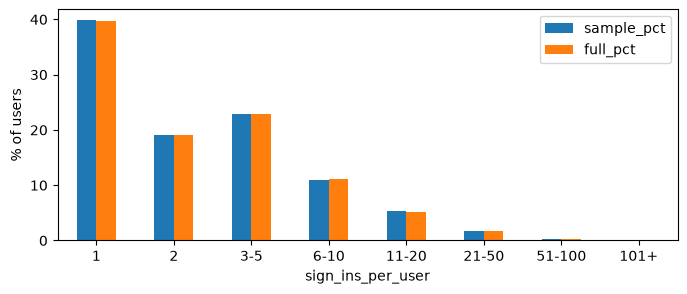

In [21]:
# The sample keeps the same mix of light and heavy users as the full data.
BINS = [(1, 1), (2, 2), (3, 5), (6, 10), (11, 20), (21, 50), (51, 100), (101, None)]


def users_per_bin(source):
    n = con.execute(f"SELECT COUNT(*) AS n FROM {source} GROUP BY user_id").fetchnumpy()["n"]
    return np.array([((n >= low) & (n <= (high or n.max()))).sum() for low, high in BINS])


in_sample, in_full = users_per_bin("sample"), users_per_bin(f"'{FULL}'")
sample_stats = pd.DataFrame({"sign_ins_per_user": [bucket_label(low, high) for low, high in BINS],
                             "sample_pct": np.round(100 * in_sample / in_sample.sum(), 2),
                             "full_pct": np.round(100 * in_full / in_full.sum(), 2)})
sample_stats.plot.bar(x="sign_ins_per_user", y=["sample_pct", "full_pct"], figsize=(8, 3), rot=0, ylabel="% of users")
print("largest gap:", round((sample_stats["sample_pct"] - sample_stats["full_pct"]).abs().max(), 2), "points")
sample_stats

In [22]:
# 4. Split by time, never at random: the models learn from the past and are judged on the future, like in real use.
# Train (60%): build history and fit models. Validation (20%): choose every setting. Test (20%): used once, at the end.
TRAIN, VAL = 0.6, 0.2
t_val, t_test = con.execute("SELECT quantile_disc(timestamp, ?), quantile_disc(timestamp, ?) FROM sample",
                            [TRAIN, TRAIN + VAL]).fetchone()
where = {"train": f"timestamp < TIMESTAMP '{t_val}'",
         "val": f"timestamp >= TIMESTAMP '{t_val}' AND timestamp < TIMESTAMP '{t_test}'",
         "test": f"timestamp >= TIMESTAMP '{t_test}'"}
periods = {}
for name, condition in where.items():
    path = WORK / f"{name}.parquet"
    con.execute(f"COPY (SELECT * FROM sample WHERE {condition} ORDER BY timestamp, row_id) TO '{path}' (FORMAT parquet)")
    periods[name] = pd.read_parquet(path)
train, val, test = periods["train"], periods["val"], periods["test"]

In [23]:
# Each sign-in's class. "simulated" is for the made-up attacks added at the very end.
def classify(logins):
    simulated = logins["is_simulated"].eq(True).to_numpy() if "is_simulated" in logins else False
    return np.select([simulated, logins["is_ato"].to_numpy(bool), logins["is_attack_ip"].to_numpy(bool),
                      logins["success"].to_numpy(bool)], ["simulated", "ato", "attack_ip", "legit"], "legit_failed")


# The periods don't overlap, and the test period has no confirmed takeovers, so takeovers can only be a side study.
pd.DataFrame({name: {"from": df["timestamp"].min(), "to": df["timestamp"].max(), "rows": len(df),
                     **pd.Series(classify(df)).value_counts().reindex(["legit", "legit_failed", "attack_ip", "ato"], fill_value=0).to_dict()}
              for name, df in periods.items()}).T

,from,to,rows,legit,legit_failed,attack_ip,ato
train,2020-02-03 12:45:16.478000,2020-09-22 19:18:37.773000,715821,497406,163022,55279,114
val,2020-09-22 19:18:38.901000,2020-12-09 14:14:16.053000,238607,163243,55156,20181,27
test,2020-12-09 14:14:18.208000,2021-02-28 23:57:31.830000,238608,152383,60725,25500,0


In [24]:
# 5. What the engine learns from. About 1 in 4 sign-ins by normal users has a wrong password.
# A wrong password proves nothing about who is there, so only successful normal sign-ins teach the engine.
# They are also stopped by the password check before any risk check, so they are never scored.
kinds = classify(train)
print("wrong-password share of normal users' sign-ins:", round((kinds == "legit_failed").sum() / np.isin(kinds, ["legit", "legit_failed"]).sum(), 4))

wrong-password share of normal users' sign-ins: 0.2468


In [25]:
# The dataset's labels decide what history learns from: only sign-ins labelled normal and successful. A live system has
# no such labels. It would learn from every sign-in it let through, including attacks it missed, so this replay
# assumes a cleaner history than a deployment would have. These successful attacker sign-ins were kept out of it:
pd.DataFrame({name: {"successful sign-ins from attacker IPs": int((df["is_attack_ip"] & df["success"] & ~df["is_ato"]).sum()),
                     "confirmed takeovers": int(df["is_ato"].sum())} for name, df in periods.items()}).T

,successful sign-ins from attacker IPs,confirmed takeovers
train,32341,114
val,11046,27
test,13102,0


In [26]:
# A sign-in, and what is remembered about each user from their earlier successful sign-ins.
FIELDS = ("ip", "asn", "country", "user_agent", "browser", "os", "device_type")


@dataclass
class LoginEvent:
    user_id: str
    timestamp: datetime
    ip: str | None
    country: str | None
    asn: int | None
    user_agent: str | None
    browser: str | None
    os: str | None
    device_type: str | None
    rtt_ms: float | None
    success: bool


@dataclass
class UserHistory:
    login_count: int = 0
    seen: dict = field(default_factory=lambda: {name: Counter() for name in FIELDS})
    hour_counts: list = field(default_factory=lambda: [0] * 24)
    last_login: datetime | None = None

In [27]:
# How often each value (network, country, browser...) appears in normal training sign-ins: what is "common".
class GlobalFrequencies:
    def __init__(self):
        self.counts = {name: Counter() for name in FIELDS}
        self.total = 0
        self.users = set()

    def add(self, event):
        for name in FIELDS:
            self.counts[name][getattr(event, name)] += 1
        self.total += 1
        self.users.add(event.user_id)

    def count(self, name, value):
        return self.counts[name][value]

    def freq(self, name, value):
        # An unseen value gets 1/(N+1) instead of 0, so its log stays finite (Freeman et al. 2016, Eq. 8).
        return max(self.counts[name][value], 1) / (self.total + 1)

In [28]:
# The history store. Every attempt, attacks included, feeds two one-hour counters (wrong passwords per user,
# accounts tried per IP); otherwise credential stuffing could never show up.
class History:
    def __init__(self, freqs):
        self.users = {}
        self.freqs = freqs
        self.total_logins = 0
        self.failures = {}
        self.ip_attempts = {}
        self.ip_users = {}

    def get_user(self, user_id):
        return self.users.get(user_id) or UserHistory()

    def update(self, event):
        user = self.users.setdefault(event.user_id, UserHistory())
        user.login_count += 1
        for name in FIELDS:
            user.seen[name][getattr(event, name)] += 1
        user.hour_counts[event.timestamp.hour] += 1
        user.last_login = event.timestamp
        self.total_logins += 1

    def record_attempt(self, event):
        if event.success is False:
            self.failures.setdefault(event.user_id, deque()).append(event.timestamp)
        self.ip_attempts.setdefault(event.ip, deque()).append((event.timestamp, event.user_id))
        self.ip_users.setdefault(event.ip, Counter())[event.user_id] += 1

    def failures_last_hour(self, user_id, now):
        times = self.failures.get(user_id)
        while times and times[0] < now - timedelta(hours=1):
            times.popleft()
        return len(times) if times else 0

    def ip_users_last_hour(self, ip, now):
        attempts = self.ip_attempts.get(ip)
        if not attempts:
            return 0
        users = self.ip_users[ip]
        while attempts and attempts[0][0] < now - timedelta(hours=1):
            _, user_id = attempts.popleft()
            users[user_id] -= 1
            if users[user_id] == 0:
                del users[user_id]
        return len(users)

In [29]:
# 6. Features for one sign-in, using only what happened before it: is the context new for this user,
# how rare is it overall, how unusual the hour is, how long since the last sign-in, and the one-hour counters.
NEW_VALUE = ("ip", "asn", "country", "browser", "os", "device_type")
FEATURES = ["prior_logins", *(f"new_{name}" for name in NEW_VALUE), "hour_deviation", "days_since_last_login",
            "user_failures_1h", "ip_distinct_users_1h", "asn_global_rarity", "country_global_rarity",
            "ua_global_rarity", "rtt_missing", "rtt_ms"]
HOUR_ANGLES = [2 * math.pi * (hour + 0.5) / 24 for hour in range(24)]


def hour_deviation(timestamp, hour_counts):
    # Hours from the user's typical hour on a 24-hour clock (so 23:00 and 01:00 are close); 6 if no history.
    x = sum(count * math.cos(angle) for count, angle in zip(hour_counts, HOUR_ANGLES))
    y = sum(count * math.sin(angle) for count, angle in zip(hour_counts, HOUR_ANGLES))
    if math.hypot(x, y) < 1e-9:
        return 6.0
    typical = (math.atan2(y, x) * 24 / (2 * math.pi)) % 24
    diff = abs(timestamp.hour + timestamp.minute / 60 - typical) % 24
    return min(diff, 24 - diff)


def extract(event, history):
    user = history.get_user(event.user_id)
    freq = history.freqs.freq
    features = {"prior_logins": float(user.login_count)}
    for name in NEW_VALUE:
        features[f"new_{name}"] = float(getattr(event, name) not in user.seen[name])
    features["hour_deviation"] = hour_deviation(event.timestamp, user.hour_counts)
    features["days_since_last_login"] = (365.0 if user.last_login is None
                                         else min(365.0, (event.timestamp - user.last_login).total_seconds() / 86400))
    features["user_failures_1h"] = float(history.failures_last_hour(event.user_id, event.timestamp))
    features["ip_distinct_users_1h"] = float(history.ip_users_last_hour(event.ip, event.timestamp))
    features["asn_global_rarity"] = -math.log(freq("asn", event.asn))
    features["country_global_rarity"] = -math.log(freq("country", event.country))
    features["ua_global_rarity"] = -math.log(freq("browser", event.browser)) - math.log(freq("os", event.os))
    features["rtt_missing"] = float(event.rtt_ms is None)
    features["rtt_ms"] = event.rtt_ms if event.rtt_ms is not None else 0.0
    return features

In [30]:
# Rows become sign-ins and are walked in time order: score first, then learn. Learning only from successful
# normal sign-ins means an attack can never teach the engine that the attacker is "normal". "Normal" comes from
# the dataset's labels, which a live system would not have (see above).
def to_events(logins):
    text = lambda value: value if isinstance(value, str) else None
    for row in logins.itertuples(index=False):
        yield LoginEvent(user_id=str(row.user_id), timestamp=row.timestamp, ip=text(row.ip), country=text(row.country),
                         asn=None if pd.isna(row.asn) else int(row.asn), user_agent=text(row.user_agent),
                         browser=text(row.browser), os=text(row.os), device_type=text(row.device_type),
                         rtt_ms=None if math.isnan(row.rtt_ms) else float(row.rtt_ms), success=bool(row.success))


def replay(logins, history, on_event=None, score_mask=None):
    for i, (event, kind) in enumerate(zip(to_events(logins), classify(logins))):
        if on_event and score_mask[i]:
            on_event(i, event)
        if kind == "legit":
            history.update(event)
        if kind != "simulated":
            history.record_attempt(event)

In [31]:
# 7. Model 1, fixed rules: points per warning sign, capped at 100. The points are set by hand before seeing any
# results (stronger evidence, more points) and are never fitted. Whether that matters is checked later.
RULES = [("new_country", 1, 30), ("new_asn", 1, 20), ("new_ip", 1, 10), ("new_device_type", 1, 15),
         ("new_browser", 1, 10), ("new_os", 1, 10), ("hour_deviation", 6, 10), ("user_failures_1h", 3, 15),
         ("ip_distinct_users_1h", 5, 25)]  # (feature, fires at or above, points)


def rule_scores(features, rules=RULES):
    total = np.zeros(len(features))
    for feature, fires_at, points in rules:
        total += points * (features[feature].to_numpy() >= fires_at)
    return np.minimum(total, 100.0)

In [32]:
# 8. Model 2, Freeman et al. (2016): how much likelier this sign-in's context is for an attacker than for this user,
# on a log scale. Each family mixes levels (IP > network > country; full browser string > browser > OS > device type)
# with weights the dataset's authors fitted for this dataset (github.com/das-group/rba-algorithm).
# Differences from the paper: those published weights replace weights learned here; a context the user has never
# shown at any level gets the reference implementation's fixed term log 4; and users with no history are scored
# (the paper leaves them out), which needs the add-one user term below.
FAMILIES = {"ip": {"ip": 0.6, "asn": 0.3, "country": 0.1},
            "user_agent": {"user_agent": 0.5386653840551359, "browser": 0.2680451498625666,
                           "os": 0.18818295100109536, "device_type": 0.0051065150812021525}}


def global_likelihood(event, freqs, weights):
    # p(x): how common this context is overall, falling back to coarser levels for unseen values.
    top, *coarser = weights
    if freqs.count(top, getattr(event, top)):
        return freqs.freq(top, getattr(event, top))
    likelihood = weights[top] * freqs.freq(top, getattr(event, top))
    for level in coarser:
        seen = freqs.count(level, getattr(event, level))
        likelihood += weights[level] * seen / ((seen + 1) * (freqs.total + 1))
    return likelihood


def local_likelihood(event, user, weights):
    # p(x | user): the user's own share of sign-ins with this value at each level.
    if user.login_count == 0:
        return 0.0
    return sum(w * user.seen[level][getattr(event, level)] for level, w in weights.items()) / user.login_count


def family_terms(event, user, freqs):
    score = 0.0
    for weights in FAMILIES.values():
        local_p = local_likelihood(event, user, weights)
        if local_p == 0:
            score += math.log(4)  # never seen at any level: treated as 4x less likely for this user than average
        else:
            score += math.log(global_likelihood(event, freqs, weights)) - math.log(local_p)
    return score

In [33]:
# The last part is p(user | attacker) / p(user | normal): attackers pick users at random, normal sign-ins come from
# each user in proportion to how often they sign in. First try: count logins and users as the history grows.
def freeman_first_try(event, history):
    user = history.get_user(event.user_id)
    users = max(len(history.users), 1)
    return family_terms(event, user, history.freqs) + (
        math.log(1 / users) - math.log((user.login_count + 1) / (history.total_logins + users)))


# Second version (why is shown below): use the fixed training-period totals instead.
def freeman_score(event, history):
    user = history.get_user(event.user_id)
    users = max(len(history.freqs.users), 1)
    return family_terms(event, user, history.freqs) + (
        math.log(1 / users) - math.log((user.login_count + 1) / (history.freqs.total + users)))

In [34]:
# Replay a period and keep each scored sign-in's features (and Freeman scores) as they were at that moment.
def attack_context(event, user):
    # How closely an attack matched the victim's usual country and device.
    if user.login_count == 0:
        return "victim_has_no_history"
    if user.seen["country"][event.country] == 0:
        return "new_country"
    known_device = all(user.seen[f][getattr(event, f)] > 0 for f in ("browser", "os", "device_type"))
    return "home_country_known_device" if known_device else "home_country_new_device"


def collect_features(logins, history, scored=("legit", "attack_ip", "ato")):
    kinds = classify(logins)
    mask = np.isin(kinds, scored)
    rows = []

    def on_event(i, event):
        user = history.get_user(event.user_id)
        features = extract(event, history)
        features["freeman_raw"] = freeman_score(event, history)
        features["freeman_first_try"] = freeman_first_try(event, history)
        features["context"] = attack_context(event, user) if kinds[i] != "legit" else ""
        features["row"] = i
        rows.append(features)

    replay(logins, history, on_event, mask)
    table = pd.DataFrame(rows)
    picked = logins.iloc[table.pop("row").to_numpy()]
    table["kind"] = kinds[mask]
    for column in ["row_id", "user_id", "timestamp", "success", "attacker_type", "target_bucket"]:
        if column in picked:
            table[column] = picked[column].to_numpy()
    return table

In [35]:
# 9. Training period: count values in normal sign-ins, then replay the period to build every user's history.
freqs = GlobalFrequencies()
for event in to_events(train[classify(train) == "legit"]):
    freqs.add(event)
history = History(freqs)
train_rows = collect_features(train, history)
train_rows[FEATURES + ["kind"]].head()

,prior_logins,new_ip,new_asn,new_country,new_browser,new_os,new_device_type,hour_deviation,days_since_last_login,user_failures_1h,ip_distinct_users_1h,asn_global_rarity,country_global_rarity,ua_global_rarity,rtt_missing,rtt_ms,kind
0,0.0,1.0,1.0,1.0,1.0,1.0,1.0,6.0,365.0,0.0,0.0,9.310501,3.513161,5.529112,1.0,0.0,attack_ip
1,0.0,1.0,1.0,1.0,1.0,1.0,1.0,6.0,365.0,0.0,0.0,3.156682,0.322810,11.293311,1.0,0.0,legit
2,0.0,1.0,1.0,1.0,1.0,1.0,1.0,6.0,365.0,0.0,0.0,0.798205,0.322810,5.322390,1.0,0.0,legit
3,0.0,1.0,1.0,1.0,1.0,1.0,1.0,6.0,365.0,0.0,0.0,13.117164,9.403592,6.317191,1.0,0.0,legit
4,0.0,1.0,1.0,1.0,1.0,1.0,1.0,6.0,365.0,0.0,0.0,5.907084,4.570995,7.621153,1.0,0.0,legit


In [36]:
# Leak check: the n-th successful sign-in of every user must see exactly n-1 earlier ones, never a later one.
normal = train_rows[train_rows["kind"] == "legit"]
print("no peeking at the future:", (normal.groupby("user_id").cumcount() == normal["prior_logins"]).all())

no peeking at the future: True


In [37]:
# Average features per class. Attacker IPs come from much rarer countries and networks, and their context is new to
# the account far more often. The one-hour counters differ only a little.
train_rows.groupby("kind")[FEATURES].mean().T.round(3)

kind,ato,attack_ip,legit
prior_logins,5.211,1.608,7.374
new_ip,0.991,1.000,0.579
new_asn,0.947,0.842,0.382
new_country,0.921,0.780,0.310
new_browser,0.886,0.856,0.566
new_os,0.754,0.812,0.463
new_device_type,0.658,0.786,0.377
hour_deviation,5.426,5.679,4.388
days_since_last_login,189.779,287.967,124.438
user_failures_1h,0.158,0.273,0.145


In [38]:
# How often each rule fires in training. The "new" rules fire far more for attackers; the two one-hour rules
# almost never fire here (the points stay as set, they are not fitted to this).
fires = {f"{feature} >= {at}": train_rows.groupby("kind")[feature].apply(lambda v: (v >= at).mean())
         for feature, at, _ in RULES}
pd.DataFrame(fires).T[["legit", "attack_ip", "ato"]].round(3)

kind,legit,attack_ip,ato
new_country >= 1,0.310,0.780,0.921
new_asn >= 1,0.382,0.842,0.947
new_ip >= 1,0.579,1.000,0.991
new_device_type >= 1,0.377,0.786,0.658
new_browser >= 1,0.566,0.856,0.886
new_os >= 1,0.463,0.812,0.754
hour_deviation >= 6,0.469,0.847,0.658
user_failures_1h >= 3,0.007,0.019,0.009
ip_distinct_users_1h >= 5,0.000,0.000,0.000


In [39]:
# 10. Validation period: carry the same history on. From here on, every setting is chosen on this period.
val_rows = collect_features(val, history)
val_check = val_rows["kind"].isin(["legit", "attack_ip"]).to_numpy()
val_attack = (val_rows.loc[val_check, "kind"] == "attack_ip").to_numpy(int)
print(f"{(val_attack == 0).sum():,} normal sign-ins, {val_attack.sum():,} attacker sign-ins")

163,243 normal sign-ins, 20,181 attacker sign-ins


In [40]:
# 11. From score to decision. A threshold is set so that a chosen share of normal sign-ins (the budget) gets a
# one-time code. First try with the rules: a plain cut-off at the top 5% of normal validation sign-ins.
rules_val = rule_scores(val_rows[val_check])
legit_rules = rules_val[val_attack == 0]
cut = np.quantile(legit_rules, 0.95)
print("cut-off:", cut, "| flagged above it:", (legit_rules > cut).mean(), "| at or above:", round((legit_rules >= cut).mean(), 4))
print("share of normal sign-ins with the top score of 100:", round((legit_rules == 100).mean(), 4))
top = val_rows[val_check][(val_attack == 0) & (rules_val == 100)]
print("of those, first-time sign-ins:", round((top["prior_logins"] == 0).mean(), 4))

cut-off: 100.0 | flagged above it: 0.0 | at or above: 0.1828
share of normal sign-ins with the top score of 100: 0.1828
of those, first-time sign-ins: 0.9974


In [41]:
# That fails: 18% of normal sign-ins tie on 100 (first-time users: nothing is known about them, so every "new" rule
# fires), so a cut-off flags 0% or 18%, never 5%.
# Fix: flag everything above the threshold, and only a share of the tie on it, sized to hit the budget exactly.
@dataclass
class Threshold:
    value: float
    tie_fraction: float = 1.0

    def flags(self, raw):  # 1 above, 0 below, the tie share on the threshold (an expected value, no randomness)
        raw = np.asarray(raw, dtype=float)
        return np.where(raw > self.value, 1.0, np.where(raw == self.value, self.tie_fraction, 0.0))


def threshold_for_rate(legit_raw, rate):
    values, counts = np.unique(np.asarray(legit_raw, dtype=float), return_counts=True)
    budget = rate * counts.sum()
    above = counts.sum() - np.cumsum(counts)  # sign-ins scoring strictly higher than each value
    i = int(np.flatnonzero(above <= budget)[0])
    return Threshold(float(values[i]), float(min(1.0, (budget - above[i]) / counts[i])))


t = threshold_for_rate(legit_rules, 0.05)
print(t, "| normal sign-ins flagged:", round(t.flags(legit_rules).mean(), 4))

Threshold(value=100.0, tie_fraction=0.2735121640640708) | normal sign-ins flagged: 0.05


In [42]:
# The budget is a usability choice: at most 1 in 20 normal sign-ins asked for a code (5%), and blocking, which is
# much harsher, for at most 1 in 200 (0.5%). Other budgets are shown later for the trade-off.
CHALLENGE_RATE, BLOCK_RATE = 0.05, 0.005


# How every model choice below is judged on validation: AUC (1 = perfect, 0.5 = coin flip) and the share of
# attacker sign-ins flagged (asked for a code or blocked) at the 5% budget. A flag is not proof that an attack was
# prevented. Choices are made on all attacker sign-ins, the label the Random Forest learns; the password-correct
# ones, the attempts a risk check actually has to catch, are shown next to them to check the choice holds.
val_password_ok = val_rows.loc[val_check, "success"].to_numpy(bool)


def judge(raw):
    raw = np.asarray(raw)
    threshold = threshold_for_rate(raw[val_attack == 0], CHALLENGE_RATE)
    return {"auc": round(float(roc_auc_score(val_attack, raw)), 4),
            "flagged": round(float(threshold.flags(raw[val_attack == 1]).mean()), 4),
            "password_correct_flagged": round(float(threshold.flags(raw[(val_attack == 1) & val_password_ok]).mean()), 4)}


print("rules:", judge(rules_val))

rules: {'auc': 0.8165, 'flagged': 0.1962, 'password_correct_flagged': 0.1814}


,freeman_first_try,freeman_raw
timestamp,,
2020-02,3.751,4.229
2020-03,3.906,4.229
2020-04,3.984,4.229
2020-05,4.041,4.229
2020-06,4.096,4.229
2020-07,4.142,4.229
2020-08,4.185,4.229
2020-09,4.220,4.229
2020-10,4.257,4.229


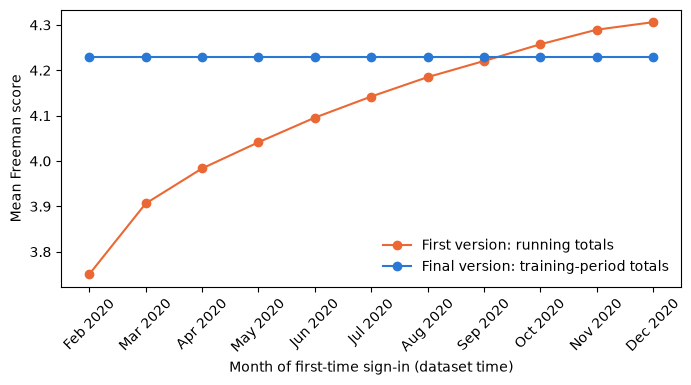

In [43]:
# 12. Freeman, first try vs second version. For first-time normal sign-ins the evidence is always the same
# (nothing seen before), so the score should be too. Average score per month:
first_time = pd.concat([train_rows, val_rows])
first_time = first_time[(first_time["kind"] == "legit") & (first_time["prior_logins"] == 0)]
monthly = first_time.groupby(first_time["timestamp"].dt.to_period("M"))[["freeman_first_try", "freeman_raw"]].mean()
fig, ax = plt.subplots(figsize=(8, 3.6))
months = monthly.index.strftime("%b %Y")
ax.plot(months, monthly["freeman_first_try"], marker="o", color="#eb6834", label="First version: running totals")
ax.plot(months, monthly["freeman_raw"], marker="o", color="#2a78d6", label="Final version: training-period totals")
ax.set(xlabel="Month of first-time sign-in (dataset time)", ylabel="Mean Freeman score")
ax.tick_params(axis="x", rotation=45)
ax.legend(loc="lower right", frameon=False)
fig.savefig(FIGURES / "freeman_drift.png", dpi=300, bbox_inches="tight")
monthly.round(3)

In [44]:
# The first try drifts upward: the running logins-per-user ratio grows as history builds up, so the same evidence
# scores higher every month and a threshold set earlier flags more and more new users. Measured on validation:
# threshold from its first half, challenge rate on its second half.
legit_val = val_rows[val_rows["kind"] == "legit"]
halfway = legit_val["timestamp"].quantile(0.5)
early, late = legit_val[legit_val["timestamp"] < halfway], legit_val[legit_val["timestamp"] >= halfway]
for column in ["freeman_first_try", "freeman_raw"]:
    late_rate = threshold_for_rate(early[column], CHALLENGE_RATE).flags(late[column]).mean()
    print(f"{column:18s} challenged in the second half: {late_rate:.2%} (target 5%)")
# The second version (training totals) keeps identical evidence at an identical score, so it is the one used.
print("Freeman:", judge(val_rows.loc[val_check, "freeman_raw"]))

freeman_first_try  challenged in the second half: 18.41% (target 5%)
freeman_raw        challenged in the second half: 5.10% (target 5%)


Freeman: {'auc': 0.7703, 'flagged': 0.1963, 'password_correct_flagged': 0.1815}


In [45]:
# 13. Model 3, Isolation Forest: unsupervised, it only learns what normal sign-ins look like and scores how easy a
# sign-in is to isolate. Trained on normal training sign-ins only; first with scikit-learn's default 100 trees.
X_normal = train_rows.loc[train_rows["kind"] == "legit", FEATURES].to_numpy()
X_val = val_rows.loc[val_check, FEATURES].to_numpy()


def iforest_scores(model, X):
    model.set_params(n_jobs=1)  # score on one thread, so the trees are added up in the same order every time
    return -model.score_samples(X)


print("Isolation Forest, 100 trees:", judge(iforest_scores(IsolationForest(random_state=SEED, n_jobs=-1).fit(X_normal), X_val)))

Isolation Forest, 100 trees: {'auc': 0.4543, 'flagged': 0.0683, 'password_correct_flagged': 0.0774}


In [46]:
# Worse than a coin flip: attackers get lower scores than normal sign-ins. Does the forest size matter?
pd.DataFrame({n: judge(iforest_scores(IsolationForest(n_estimators=n, random_state=SEED, n_jobs=-1).fit(X_normal), X_val))
              for n in (50, 100, 200, 400)}).T

,auc,flagged,password_correct_flagged
50,0.4703,0.0976,0.1120
100,0.4543,0.0683,0.0774
200,0.4389,0.0658,0.0777
400,0.4364,0.0581,0.0677


In [47]:
# No size beats a coin flip and more trees make it slightly worse, so it isn't a tuning problem. On validation,
# attackers come from rarer countries and networks but use more common browsers than normal users. Without labels,
# the forest can't know which kind of "unusual" points to an attacker.
val_rows[val_rows["kind"].isin(["legit", "attack_ip"])].groupby("kind")[
    ["ua_global_rarity", "days_since_last_login", "country_global_rarity", "asn_global_rarity"]].mean().round(2)

,ua_global_rarity,days_since_last_login,country_global_rarity,asn_global_rarity
kind,,,,
attack_ip,9.94,277.93,2.23,3.67
legit,12.29,94.07,1.06,2.83


In [48]:
# Kept as the unsupervised baseline, at 200 trees (twice the default; no size beats a coin flip anyway).
iforest = IsolationForest(n_estimators=200, random_state=SEED, n_jobs=-1).fit(X_normal)
iforest.set_params(n_jobs=1)
print("Isolation Forest:", judge(-iforest.score_samples(X_val)))

Isolation Forest: {'auc': 0.4389, 'flagged': 0.0658, 'password_correct_flagged': 0.0777}


In [49]:
# 14. Model 4, Random Forest: supervised, it learns from labelled examples. Normal successful sign-ins (0) vs real
# sign-ins from known attacker IPs (1), training period only. It never sees the simulated attacks made later,
# or it would learn how we made them.
labelled = train_rows[train_rows["kind"].isin(["legit", "attack_ip"])]
X_rf, y_rf = labelled[FEATURES].to_numpy(), (labelled["kind"] == "attack_ip").to_numpy(int)
print("normal:", (y_rf == 0).sum(), "| attacker:", (y_rf == 1).sum(), "| ratio:", round((y_rf == 0).sum() / (y_rf == 1).sum(), 1))


def forest(**settings):
    model = RandomForestClassifier(random_state=SEED, n_jobs=-1, **settings).fit(X_rf, y_rf)
    model.set_params(n_jobs=1)
    return model


def nodes(model):
    return sum(tree.tree_.node_count for tree in model.estimators_)


baseline = forest(n_estimators=100)
print("defaults (100 trees):", judge(baseline.predict_proba(X_val)[:, 1]), f"| {nodes(baseline):,} nodes")

normal: 497406 | attacker: 55279 | ratio: 9.0


defaults (100 trees): {'auc': 0.9391, 'flagged': 0.6421, 'password_correct_flagged': 0.6256} | 3,208,790 nodes


In [50]:
# Already far better than the other three. Leaf size: how many training sign-ins each final leaf must hold. The
# default 1 lets trees memorise single sign-ins. Compared at 100 trees to keep it quick.
leaves = {}
for leaf in (1, 5, 20, 50, 100):
    model = forest(n_estimators=100, min_samples_leaf=leaf)
    leaves[leaf] = {**judge(model.predict_proba(X_val)[:, 1]), "nodes": nodes(model)}
pd.DataFrame(leaves).T

,auc,flagged,password_correct_flagged,nodes
1,0.9391,0.6421,0.6256,3208790.0
5,0.9527,0.6573,0.6387,1055956.0
20,0.9523,0.6518,0.6337,389496.0
50,0.9515,0.6388,0.6228,199888.0
100,0.9504,0.6350,0.6233,119604.0


In [51]:
# Leaf 1 has the lowest AUC and by far the most nodes. 5 is best by a hair, and 20 is within 0.001 AUC and half a
# point of it with about a third of the nodes (a smaller, faster model). So: leaf size 20.
MIN_LEAF = 20

# Attackers are 1 in 10 labels. The usual fix is to weight the classes equally ("balanced"). Does it help here?
balanced = forest(n_estimators=100, min_samples_leaf=MIN_LEAF, class_weight="balanced")
print("balanced:  ", judge(balanced.predict_proba(X_val)[:, 1]))
print("unweighted:", leaves[MIN_LEAF])

balanced:   {'auc': 0.9508, 'flagged': 0.6223, 'password_correct_flagged': 0.5936}
unweighted: {'auc': 0.9523, 'flagged': 0.6518, 'password_correct_flagged': 0.6337, 'nodes': 389496}


In [52]:
# Balancing makes it worse here (fewer attacker sign-ins flagged at the 5% budget), so the classes stay unweighted.
# Number of trees: fit 300 and score with the first k of them (a forest's first k trees are a k-tree forest).
rforest = forest(n_estimators=300, min_samples_leaf=MIN_LEAF)
tree_probs = np.array([tree.predict_proba(X_val)[:, 1] for tree in rforest.estimators_])
pd.DataFrame({k: {**judge(tree_probs[:k].mean(axis=0)), "distinct_normal_scores": len(np.unique(tree_probs[:k].mean(axis=0)[val_attack == 0]))}
              for k in (10, 25, 50, 100, 200, 300)}).T

,auc,flagged,password_correct_flagged,distinct_normal_scores
10,0.9510,0.6444,0.6266,43387.0
25,0.9517,0.6486,0.6304,61524.0
50,0.9522,0.6506,0.6323,66983.0
100,0.9523,0.6518,0.6337,72433.0
200,0.9525,0.6515,0.6315,83628.0
300,0.9525,0.6523,0.6330,90919.0


Random Forest: {'auc': 0.9525, 'flagged': 0.6523, 'password_correct_flagged': 0.633}


country_global_rarity    0.359
asn_global_rarity        0.240
ip_distinct_users_1h     0.071
days_since_last_login    0.068
new_ip                   0.055
new_country              0.040
dtype: float64

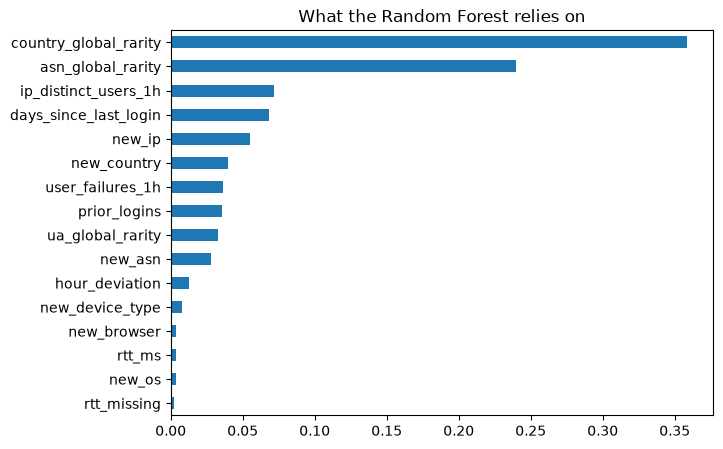

In [53]:
# Accuracy stops improving after about 100 trees, but more trees keep making the scores finer (fewer ties at the
# threshold), and scoring stays at a few milliseconds. So the final Random Forest is 300 trees, leaf 20, unweighted.
print("Random Forest:", judge(rforest.predict_proba(X_val)[:, 1]))
importance = pd.Series(rforest.feature_importances_, index=FEATURES).sort_values()
importance.plot.barh(figsize=(7, 5), title="What the Random Forest relies on")
importance.sort_values(ascending=False).round(3).head(6)

In [54]:
# 15. The four final models. Raw score of each for a table of sign-ins (higher = riskier).
MODELS = ["rules", "freeman", "iforest", "rforest"]
NAMES = {"rules": "Fixed rules", "freeman": "Freeman et al.", "iforest": "Isolation Forest", "rforest": "Random Forest"}
COLORS = {"rules": "#eda100", "freeman": "#eb6834", "iforest": "#1baf7a", "rforest": "#2a78d6"}
LINES = {"rules": ":", "freeman": "--", "iforest": "-.", "rforest": "-"}
MARKERS = {"rules": "D", "freeman": "s", "iforest": "^", "rforest": "o"}
LEGEND_ORDER = ["rforest", "freeman", "iforest", "rules"]
plt.rcParams.update({"font.size": 12, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e5e5e5"})


def raw_scores(table):
    X = table[FEATURES].to_numpy()
    return {"rules": rule_scores(table), "freeman": table["freeman_raw"].to_numpy(),
            "iforest": -iforest.score_samples(X), "rforest": rforest.predict_proba(X)[:, 1]}

In [55]:
# Thresholds for each model on its normal validation sign-ins: code (5%), block (0.5%), and other budgets for later.
BUDGETS = [0.01, 0.05, 0.10, 0.20]
val_raw = raw_scores(val_rows)
val_legit = (val_rows["kind"] == "legit").to_numpy()
val_attackers = (val_rows["kind"] == "attack_ip").to_numpy()
otp, block, budgets, calibration, summary = {}, {}, {}, {}, []
for name in MODELS:
    legit_raw = val_raw[name][val_legit]
    otp[name], block[name] = threshold_for_rate(legit_raw, CHALLENGE_RATE), threshold_for_rate(legit_raw, BLOCK_RATE)
    budgets[name] = {rate: threshold_for_rate(legit_raw, rate) for rate in BUDGETS}
    calibration[name] = np.sort(legit_raw)
    summary.append({"model": name, "legit_challenged": otp[name].flags(legit_raw).mean(),
                    "legit_blocked": block[name].flags(legit_raw).mean(),
                    "attack_ip_flagged": otp[name].flags(val_raw[name][val_attackers]).mean()})
pd.DataFrame(summary).round(4)

,model,legit_challenged,legit_blocked,attack_ip_flagged
0,rules,0.05,0.005,0.1962
1,freeman,0.05,0.005,0.1963
2,iforest,0.05,0.005,0.0658
3,rforest,0.05,0.005,0.6523


In [56]:
# The trade-off on validation: attacker sign-ins flagged as the budget grows. Rules and Freeman jump between 10% and 20%:
# below about 18% their whole budget goes to first-time sign-ins tied at the top score.
pd.DataFrame({name: {rate: budgets[name][rate].flags(val_raw[name][val_attackers]).mean() for rate in BUDGETS}
              for name in MODELS}).rename_axis("budget").round(3)

,rules,freeman,iforest,rforest
budget,,,,
0.01,0.039,0.039,0.018,0.315
0.05,0.196,0.196,0.066,0.652
0.10,0.392,0.393,0.122,0.921
0.20,0.735,0.724,0.208,0.967


In [57]:
# The 0-100 risk score shown to people: the % of normal validation sign-ins this one is riskier than.
def risk_score(name, raw):
    return (100 * np.searchsorted(calibration[name], np.asarray(raw, dtype=float), side="left")) // len(calibration[name])


print({name: int(risk_score(name, [np.median(val_raw[name][val_attackers])])[0]) for name in MODELS}, "<- median attacker")

{'rules': 81, 'freeman': 81, 'iforest': 39, 'rforest': 96} <- median attacker


In [58]:
# The rule points were set by hand. Do the exact numbers matter? Scale all of them, and each one alone, by ±25%.
variants = {"as set": RULES}
for factor in (0.75, 1.25):
    variants[f"all x{factor}"] = [(f, at, p * factor) for f, at, p in RULES]
    for i, (feature, at, points) in enumerate(RULES):
        variants[f"{feature} x{factor}"] = RULES[:i] + [(feature, at, points * factor)] + RULES[i + 1:]
sensitivity = pd.DataFrame({name: judge(rule_scores(val_rows[val_check], rules)) for name, rules in variants.items()}).T
print(sensitivity.agg(["min", "max"]))
# Results barely move, so the hand-set points are not a weak spot.

        auc  flagged  password_correct_flagged
min  0.8108   0.1951                    0.1808
max  0.8222   0.2075                    0.1862


In [59]:
# 16. Simulated attacks, a separate and labelled experiment in the test period only. Each copies a real sign-in of
# another user, aimed at a chosen victim. naive: any network and device; vpn: the victim's country; targeted: also
# the victim's device. 500 victims per history bucket, one attack of each type.
# They draw on test-period information: victims are users who sign in during the test period, each attack is timed
# between the victim's real test-period sign-ins, and the victim's usual country and device, like the copied networks
# and devices, come from sign-ins in all three periods, the test period included.
ATTACK_TYPES = ["naive", "vpn", "targeted"]
PER_BUCKET = 500
NETWORK = ["ip", "asn", "country", "region", "city", "rtt_ms"]
DEVICE = ["user_agent", "browser", "os", "device_type"]
DEVICE_KEY = ["browser", "os", "device_type"]


def to_us(timestamps):
    return timestamps.astype("datetime64[us]").astype("int64").to_numpy()


def bucket_window(login_us, low, high, start, end):
    # Time range in the test period where the user has between low and high earlier sign-ins.
    if low > len(login_us):
        return None
    begin = start if low == 0 else max(start, int(login_us[low - 1]))
    finish = end if high is None or high >= len(login_us) else min(end, int(login_us[high]))
    return (begin, finish) if finish - begin > 2 else None


def choose_victims(login_us_by_user, start, end, rng):
    # Scarcest buckets pick first, and nobody is a victim in two buckets.
    used, victims = set(), {}
    for low, high in reversed(BUCKETS):
        eligible = []
        for user in sorted(login_us_by_user):
            window = None if user in used else bucket_window(login_us_by_user[user], low, high, start, end)
            if window:
                eligible.append((user, window))
        picked = rng.choice(len(eligible), size=PER_BUCKET, replace=False)
        victims[bucket_label(low, high)] = [eligible[i] for i in sorted(picked)]
        used.update(user for user, _ in victims[bucket_label(low, high)])
    return victims

In [60]:
# Network and device are copied from real sign-ins of other users; nothing is invented.
def most_common_per_user(logins, columns):
    counts = logins.groupby(["user_id", *columns], dropna=False).size().rename("n").reset_index()
    counts = counts.sort_values(["user_id", "n", *columns], ascending=[True, False, *[True] * len(columns)])
    return counts.drop_duplicates("user_id").set_index("user_id")[columns]


def pick_row(candidates, pool_users, victim, rng):
    # Prefer another user's sign-in, so the attacker doesn't reuse the victim's own IP or browser.
    for _ in range(20):
        row = int(candidates[rng.integers(len(candidates))])
        if pool_users[row] != victim:
            return row
    return row


def simulate(victims, pool, rng):
    pool = pool.reset_index(drop=True)
    pool_users, all_rows = pool["user_id"].to_numpy(), np.arange(len(pool))
    by_country, by_device = pool.groupby("country").indices, pool.groupby(DEVICE_KEY).indices
    home_country = most_common_per_user(pool, ["country"])["country"]
    home_device = most_common_per_user(pool, DEVICE_KEY)
    records = []
    for label, entries in victims.items():
        for victim, (begin, finish) in entries:
            country_rows = by_country.get(home_country[victim], all_rows)
            device_rows = by_device.get(tuple(home_device.loc[victim]), all_rows)
            for attacker_type in ATTACK_TYPES:
                network = pool.iloc[pick_row(all_rows if attacker_type == "naive" else country_rows, pool_users, victim, rng)]
                device = pool.iloc[pick_row(device_rows if attacker_type == "targeted" else all_rows, pool_users, victim, rng)]
                records.append({"timestamp_us": int(rng.integers(begin + 1, finish)), "user_id": victim,
                                **network[NETWORK].to_dict(), **device[DEVICE].to_dict(), "success": True,
                                "attacker_type": attacker_type, "target_bucket": label})
    attacks = pd.DataFrame(records)
    attacks.insert(0, "timestamp", pd.to_datetime(attacks.pop("timestamp_us"), unit="us"))
    attacks.insert(0, "row_id", -np.arange(1, len(attacks) + 1))  # negative ids never clash with dataset rows
    attacks["is_attack_ip"], attacks["is_ato"], attacks["is_simulated"] = False, False, True
    return attacks.sort_values(["timestamp", "row_id"]).reset_index(drop=True)

In [61]:
all_logins = pd.concat([train, val, test], ignore_index=True)
pool = all_logins[~all_logins["is_attack_ip"] & ~all_logins["is_ato"] & all_logins["success"]]
start, end = int(to_us(test["timestamp"]).min()), int(to_us(test["timestamp"]).max()) + 1
login_us_by_user = {user: np.sort(to_us(group)) for user, group in pool.groupby("user_id")["timestamp"]}
rng = np.random.default_rng(SEED)
attacks = simulate(choose_victims(login_us_by_user, start, end, rng), pool, rng)
attacks.pivot_table(index="target_bucket", columns="attacker_type", values="row_id", aggfunc="count").loc[
    [bucket_label(*b) for b in BUCKETS], ATTACK_TYPES]

attacker_type,naive,vpn,targeted
target_bucket,,,
0,500,500,500
1-2,500,500,500
3-5,500,500,500
6-10,500,500,500
11-20,500,500,500
21+,500,500,500


In [62]:
# 17. The test period, used once with everything fixed: real sign-ins plus the simulated attacks, scored in time
# order with the history carried on. Simulated attacks never enter any history.
# Note: in the project, two settings were first revised after an earlier run had already scored this period: the
# Freeman user term (section 12) and the Random Forest's class weights (section 14). Both are justified above on
# validation data alone, but this test period was not untouched when they were chosen.
logins = pd.concat([test, attacks], ignore_index=True).sort_values(["timestamp", "row_id"], kind="stable").reset_index(drop=True)
table = collect_features(logins, history, scored=("legit", "attack_ip", "simulated"))
test_raw = raw_scores(table)
for name in MODELS:
    table[f"{name}_raw"] = test_raw[name]
    table[f"{name}_score"] = risk_score(name, test_raw[name])
    table[f"{name}_challenge"] = otp[name].flags(test_raw[name])
    table[f"{name}_block"] = block[name].flags(test_raw[name])
prior = table["prior_logins"].to_numpy()
table["bucket"] = None
for low, high in BUCKETS:
    table.loc[(prior >= low) & (prior <= (np.inf if high is None else high)), "bucket"] = bucket_label(low, high)
table["kind"].value_counts()

kind
legit        152383
attack_ip     25500
simulated      9000
Name: count, dtype: int64

In [63]:
# Helpers for the results. Rates get 95% intervals from a bootstrap over accounts: accounts are resampled, not single
# attempts, because one account can be tried many times, and the tie-split flags are fractions, not 0 or 1.
# (A Wilson interval assumes independent 0/1 attempts; it is kept only to compare.)
BOOTSTRAP = 2000


def account_bootstrap(flags, accounts, seed=SEED):
    """Rate of each flag column with a 95% interval, resampling accounts with replacement."""
    flags = np.asarray(flags, dtype=float)
    flags = flags[:, None] if flags.ndim == 1 else flags
    if len(flags) == 0:
        return np.full(flags.shape[1], np.nan), np.full(flags.shape[1], np.nan), np.full(flags.shape[1], np.nan), 0
    _, account = np.unique(np.asarray(accounts).astype(str), return_inverse=True)
    n_accounts = account.max() + 1
    sums = np.column_stack([np.bincount(account, weights=flags[:, j], minlength=n_accounts) for j in range(flags.shape[1])])
    counts = np.bincount(account, minlength=n_accounts).astype(float)
    rng, rates = np.random.default_rng(seed), []
    for size in np.diff(np.linspace(0, BOOTSTRAP, max(2, BOOTSTRAP * n_accounts // 2_000_000 + 2), dtype=int)):
        picks = rng.integers(0, n_accounts, size=(size, n_accounts))
        rates.append(sums[picks].sum(axis=1) / counts[picks].sum(axis=1)[:, None])
    low, high = np.percentile(np.concatenate(rates), [2.5, 97.5], axis=0)
    return flags.mean(axis=0), low, high, int(n_accounts)


def wilson(hits, n, z=1.96):
    if n == 0:
        return np.nan, np.nan
    p = hits / n
    centre = (p + z * z / (2 * n)) / (1 + z * z / n)
    half = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / (1 + z * z / n)
    return max(0.0, centre - half), min(1.0, centre + half)


def equal_error_rate(labels, scores):
    fpr, tpr, _ = roc_curve(labels, scores)
    i = np.argmin(np.abs(fpr - (1 - tpr)))
    return float((fpr[i] + 1 - tpr[i]) / 2)


# The main security comparison is the attacker-IP sign-ins that had the right password: a wrong password is stopped
# by the password check anyway. All attacker-IP sign-ins and the simulated attacks are kept as secondary sets.
ATTACK_SETS = {"password_correct": (table["kind"] == "attack_ip") & table["success"],
               "all_attacker_ip": table["kind"] == "attack_ip",
               "simulated": table["kind"] == "simulated"}
MAIN = ATTACK_SETS["password_correct"]
is_legit = table["kind"] == "legit"

In [64]:
# How many attempts and how many different accounts each set has. Many accounts are tried more than once, so the
# accounts, not the attempts, are the independent units behind the intervals.
pd.DataFrame({name: {"attempts": int(mask.sum()), "accounts": table.loc[mask, "user_id"].nunique(),
                     "most attempts on one account": int(table.loc[mask, "user_id"].value_counts().max())}
              for name, mask in {**ATTACK_SETS, "legit": is_legit}.items()}).T

,attempts,accounts,most attempts on one account
password_correct,13102,8163,47
all_attacker_ip,25500,14792,49
simulated,9000,3000,3
legit,152383,70164,233


In [65]:
# Results at the 5% budget: how well each model separates each attack set from legitimate sign-ins, and how many
# attempts it flags (code or block), with account-bootstrap 95% intervals.
rows = []
for name in MODELS:
    raw, challenged, blocked = table[f"{name}_raw"], table[f"{name}_challenge"], table[f"{name}_block"]
    for attack_set, is_attack in ATTACK_SETS.items():
        both = is_legit | is_attack
        labels, flags = is_attack[both].to_numpy(int), challenged[both].to_numpy()
        rate, low, high, accounts = account_bootstrap(challenged[is_attack], table.loc[is_attack, "user_id"])
        rows.append({"attack_set": attack_set, "model": name, "attempts": int(is_attack.sum()), "accounts": accounts,
                     "roc_auc": roc_auc_score(labels, raw[both]), "eer": equal_error_rate(labels, raw[both].to_numpy()),
                     "flagged": rate[0], "flagged_low": low[0], "flagged_high": high[0], "blocked": blocked[is_attack].mean(),
                     "legit_challenged": challenged[is_legit].mean(), "legit_blocked": blocked[is_legit].mean(),
                     "precision": flags[labels == 1].sum() / flags.sum()})
overall = pd.DataFrame(rows).set_index(["attack_set", "model"])
overall.round(3)

,,attempts,accounts,roc_auc,eer,flagged,flagged_low,flagged_high,blocked,legit_challenged,legit_blocked,precision
attack_set,model,,,,,,,,,,,
password_correct,rules,13102,8163,0.790,0.270,0.183,0.179,0.187,0.018,0.052,0.005,0.233
all_attacker_ip,rules,25500,14792,0.806,0.242,0.197,0.194,0.200,0.020,0.052,0.005,0.389
simulated,rules,9000,3000,0.714,0.325,0.050,0.046,0.053,0.005,0.052,0.005,0.054
password_correct,freeman,13102,8163,0.753,0.296,0.183,0.179,0.188,0.018,0.052,0.005,0.233
all_attacker_ip,freeman,25500,14792,0.780,0.256,0.197,0.194,0.201,0.020,0.052,0.005,0.389
simulated,freeman,9000,3000,0.729,0.286,0.049,0.045,0.052,0.007,0.052,0.005,0.053
password_correct,iforest,13102,8163,0.429,0.542,0.069,0.059,0.080,0.009,0.074,0.009,0.074
all_attacker_ip,iforest,25500,14792,0.376,0.586,0.056,0.049,0.063,0.009,0.074,0.009,0.112
simulated,iforest,9000,3000,0.540,0.454,0.087,0.081,0.093,0.008,0.074,0.009,0.065


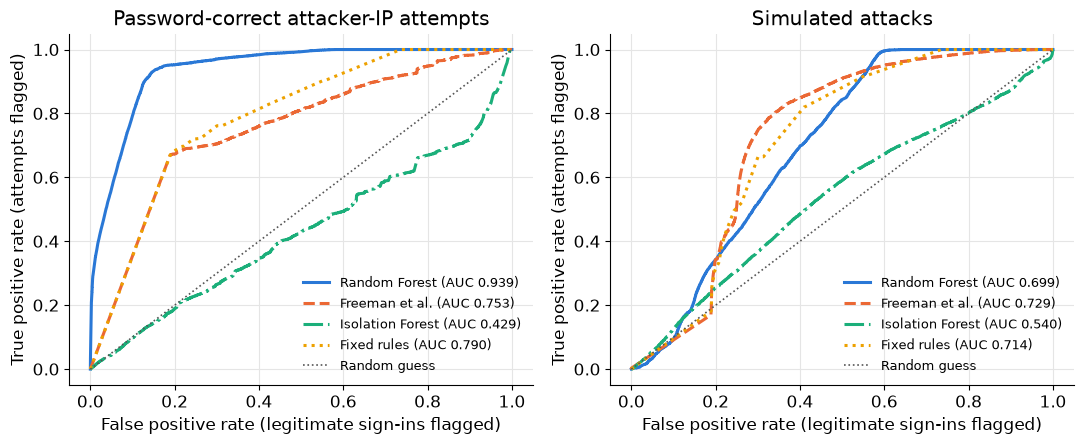

In [66]:
# ROC curves: password-correct attacker-IP sign-ins (the main comparison) and simulated attacks.
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
for ax, attack_set, title in [(axes[0], "password_correct", "Password-correct attacker-IP attempts"),
                              (axes[1], "simulated", "Simulated attacks")]:
    both = is_legit | ATTACK_SETS[attack_set]
    labels = ATTACK_SETS[attack_set][both].to_numpy(int)
    for name in LEGEND_ORDER:
        fpr, tpr, _ = roc_curve(labels, table.loc[both, f"{name}_raw"])
        ax.plot(fpr, tpr, color=COLORS[name], linestyle=LINES[name], linewidth=2.2,
                label=f"{NAMES[name]} (AUC {overall.loc[(attack_set, name), 'roc_auc']:.3f})")
    ax.plot([0, 1], [0, 1], color="#555555", linestyle=":", linewidth=1.2, label="Random guess")
    ax.set(xlabel="False positive rate (legitimate sign-ins flagged)", ylabel="True positive rate (attempts flagged)", title=title)
    ax.legend(loc="lower right", fontsize=9.5, frameon=False)
fig.tight_layout()
fig.savefig(FIGURES / "roc_curves.png", dpi=300, bbox_inches="tight")

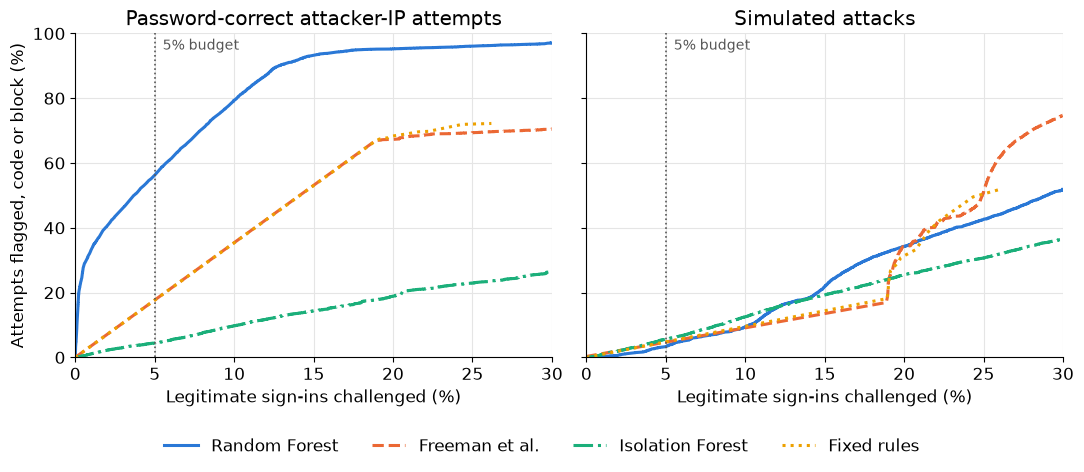

In [67]:
# Trade-off on the test period: attempts flagged against legitimate sign-ins challenged, for every possible threshold.
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), sharey=True)
for ax, attack_set, title in [(axes[0], "password_correct", "Password-correct attacker-IP attempts"),
                              (axes[1], "simulated", "Simulated attacks")]:
    both = is_legit | ATTACK_SETS[attack_set]
    for name in LEGEND_ORDER:
        fpr, tpr, _ = roc_curve(ATTACK_SETS[attack_set][both].to_numpy(int), table.loc[both, f"{name}_raw"])
        keep = fpr <= 0.30
        ax.plot(100 * fpr[keep], 100 * tpr[keep], color=COLORS[name], linestyle=LINES[name], linewidth=2.2, label=NAMES[name])
    ax.axvline(5, color="#555555", linestyle=":", linewidth=1.2)
    ax.text(5.5, 95, "5% budget", fontsize=10, color="#555555")
    ax.set(xlim=(0, 30), ylim=(0, 100), xlabel="Legitimate sign-ins challenged (%)", title=title)
axes[0].set_ylabel("Attempts flagged, code or block (%)")
handles, legend_labels = axes[0].get_legend_handles_labels()
fig.legend(handles, legend_labels, loc="lower center", ncol=4, frameon=False, bbox_to_anchor=(0.5, -0.04))
fig.tight_layout(rect=(0, 0.06, 1, 1))
fig.savefig(FIGURES / "security_usability_tradeoff.png", dpi=300, bbox_inches="tight")

In [68]:
# Every budget on the test period: share of attempts flagged in each set, and the share of legitimate sign-ins
# actually challenged (thresholds were set on validation, so they drift a little on newer data).
by_budget = pd.DataFrame([{"model": name, "budget": rate, "legit_challenged": flags[is_legit].mean(),
                           **{f"{attack_set}_flagged": flags[mask].mean() for attack_set, mask in ATTACK_SETS.items()}}
                          for name in MODELS for rate in BUDGETS
                          for flags in [budgets[name][rate].flags(table[f"{name}_raw"])]])
by_budget.set_index(["budget", "model"]).round(3)

,,legit_challenged,password_correct_flagged,all_attacker_ip_flagged,simulated_flagged
budget,model,,,,
0.01,rules,0.010,0.037,0.039,0.010
0.05,rules,0.052,0.183,0.197,0.050
0.10,rules,0.103,0.366,0.394,0.099
0.20,rules,0.204,0.686,0.734,0.324
0.01,freeman,0.010,0.037,0.039,0.012
0.05,freeman,0.052,0.183,0.197,0.049
0.10,freeman,0.104,0.367,0.395,0.094
0.20,freeman,0.201,0.674,0.724,0.343
0.01,iforest,0.017,0.019,0.016,0.017


In [69]:
# Validation thresholds challenge a little more or less than planned on the test period, so the models are also compared
# at equal test cost: each test ROC curve read at the same share of legitimate sign-ins challenged. Those thresholds are
# only known afterwards, so this checks the ranking; it is not a setting a service could use.
def flagged_at_cost(mask, name, cost):
    both = is_legit | mask
    fpr, tpr, _ = roc_curve(mask[both].to_numpy(int), table.loc[both, f"{name}_raw"])
    return float(np.interp(cost, fpr, tpr))


pd.DataFrame({(attack_set, name): {cost: flagged_at_cost(ATTACK_SETS[attack_set], name, cost) for cost in BUDGETS}
              for attack_set in ("password_correct", "all_attacker_ip") for name in MODELS}).rename_axis("test cost").round(3)

password_correct                         all_attacker_ip                        
                     rules freeman iforest rforest           rules freeman iforest rforest
test cost                                                                                 
0.01                 0.035   0.035   0.011   0.332           0.038   0.038   0.010   0.276
0.05                 0.177   0.177   0.044   0.563           0.190   0.191   0.036   0.559
0.10                 0.354   0.354   0.097   0.793           0.381   0.381   0.080   0.824
0.20                 0.684   0.673   0.189   0.952           0.732   0.723   0.158   0.968

In [70]:
# Cold start: results by how many successful sign-ins the user had before this one, with account-bootstrap intervals.
populations = {"legit": is_legit, **ATTACK_SETS}
order = [bucket_label(low, high) for low, high in BUCKETS]
challenge_columns = [f"{name}_challenge" for name in MODELS]
cold_rows = []
for population, mask in populations.items():
    for bucket in order:
        part = mask & (table["bucket"] == bucket)
        rate, low, high, accounts = account_bootstrap(table.loc[part, challenge_columns].to_numpy(), table.loc[part, "user_id"])
        cold_rows += [{"population": population, "model": name, "bucket": bucket, "n": int(part.sum()), "accounts": accounts,
                       "rate": rate[j], "ci_low": low[j], "ci_high": high[j]} for j, name in enumerate(MODELS)]
cold = pd.DataFrame(cold_rows)
cold.pivot_table(index=["population", "model"], columns="bucket", values="rate")[order].round(3)

bucket                        0    1-2    3-5   6-10  11-20    21+
population       model                                            
all_attacker_ip  freeman  0.274  0.000  0.000  0.000  0.000  0.000
                 iforest  0.021  0.101  0.134  0.258  0.220  0.391
                 rforest  0.729  0.463  0.379  0.384  0.419  0.415
                 rules    0.274  0.000  0.000  0.000  0.001  0.000
legit            freeman  0.274  0.000  0.000  0.000  0.000  0.000
                 iforest  0.036  0.111  0.092  0.076  0.062  0.062
                 rforest  0.297  0.034  0.007  0.002  0.001  0.001
                 rules    0.274  0.000  0.000  0.000  0.000  0.000
password_correct freeman  0.274  0.000  0.000  0.000  0.000  0.000
                 iforest  0.020  0.112  0.138  0.259  0.230  0.393
                 rforest  0.731  0.476  0.410  0.395  0.422  0.432
                 rules    0.274  0.000  0.000  0.000  0.001  0.000
simulated        freeman  0.274  0.013  0.002  0.001  0.001  0.001
                 iforest  0.007  0.071  0.085  0.083  0.118  0.159
                 rforest  0.238  0.071  0.005  0.005  0.005  0.004
                 rules    0.274  0.011  0.006  0.002  0.003  0.002

In [71]:
# The main set and the legitimate sign-ins in detail: attempts and accounts per bucket, and each model's rate (%)
# with its 95% interval.
def detail(population):
    part = cold[cold["population"] == population].copy()
    part["rate [95% CI]"] = [f"{100 * r:.1f} [{100 * lo:.1f}-{100 * hi:.1f}]"
                             for r, lo, hi in zip(part["rate"], part["ci_low"], part["ci_high"])]
    counts = part.drop_duplicates("bucket").set_index("bucket")[["n", "accounts"]].T
    return pd.concat([counts, part.pivot(index="model", columns="bucket", values="rate [95% CI]")])[order]


main = cold[cold["population"] == "password_correct"]
display(detail("password_correct"))
detail("legit")

bucket,0,1-2,3-5,6-10,11-20,21+
n,8762,2155,1013,521,313,338
accounts,6043,1315,511,248,135,67
freeman,27.4 [27.4-27.4],0.0 [0.0-0.0],0.0 [0.0-0.0],0.0 [0.0-0.0],0.0 [0.0-0.0],0.0 [0.0-0.0]
iforest,2.0 [1.6-2.5],11.2 [9.2-13.5],13.8 [10.5-17.9],25.9 [19.4-32.6],23.0 [16.0-31.8],39.3 [16.9-55.6]
rforest,73.1 [72.0-74.2],47.6 [44.8-50.3],41.0 [36.7-45.0],39.5 [31.2-48.5],42.2 [28.8-54.1],43.2 [23.8-58.9]
rules,27.4 [27.4-27.4],0.0 [0.0-0.0],0.0 [0.0-0.0],0.0 [0.0-0.0],0.1 [0.0-0.3],0.0 [0.0-0.0]


bucket,0,1-2,3-5,6-10,11-20,21+
n,28778,30442,25742,23448,20610,23363
accounts,28778,23706,16883,12076,7484,3207
freeman,27.4 [27.4-27.4],0.0 [0.0-0.0],0.0 [0.0-0.0],0.0 [0.0-0.0],0.0 [0.0-0.0],0.0 [0.0-0.0]
iforest,3.6 [3.4-3.8],11.1 [10.8-11.5],9.2 [8.8-9.6],7.6 [7.2-8.0],6.2 [5.8-6.6],6.2 [5.1-7.4]
rforest,29.7 [29.2-30.3],3.4 [3.2-3.6],0.7 [0.6-0.8],0.2 [0.2-0.3],0.1 [0.0-0.1],0.1 [0.1-0.2]
rules,27.4 [27.4-27.4],0.0 [0.0-0.0],0.0 [0.0-0.0],0.0 [0.0-0.0],0.0 [0.0-0.0],0.0 [0.0-0.0]


In [72]:
# Why the bootstrap: the Wilson interval treats every attempt as independent and every flag as 0 or 1. Where accounts
# are tried repeatedly it comes out narrower than the account bootstrap (Random Forest, main set).
rf = main[main["model"] == "rforest"].set_index("bucket").loc[order]
pd.DataFrame({"attempts per account": (rf["n"] / rf["accounts"]).round(2),
              "Wilson width": [100 * np.subtract(*wilson(r * n, n)[::-1]) for r, n in zip(rf["rate"], rf["n"])],
              "bootstrap width": 100 * (rf["ci_high"] - rf["ci_low"])}).round(1).T

bucket,0,1-2,3-5,6-10,11-20,21+
attempts per account,1.4,1.6,2.0,2.1,2.3,5.0
Wilson width,1.9,4.2,6.0,8.4,10.9,10.5
bootstrap width,2.2,5.5,8.3,17.3,25.3,35.1


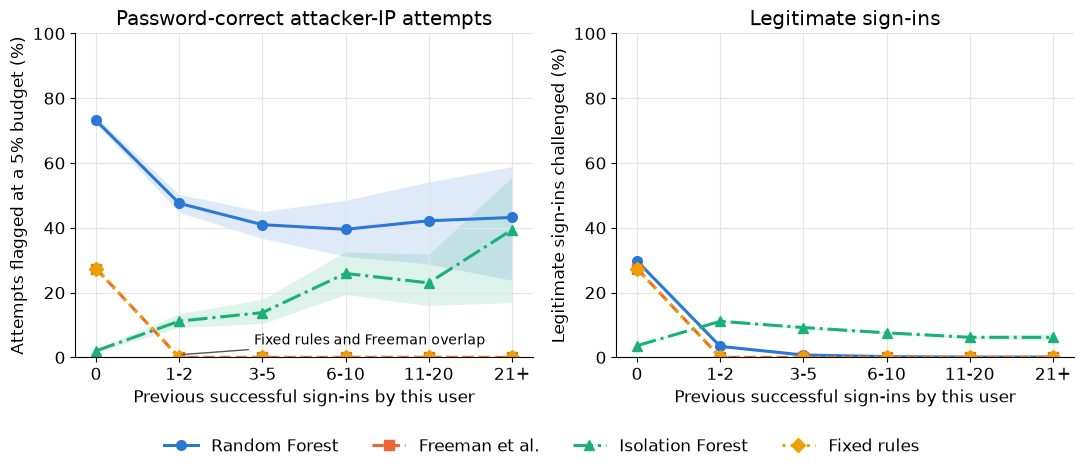

In [73]:
# Cold start chart: password-correct attempts flagged and legitimate sign-ins challenged, by history (Freeman and the
# fixed rules overlap).
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
for ax, population, title, ylabel in [
        (axes[0], "password_correct", "Password-correct attacker-IP attempts", "Attempts flagged at a 5% budget (%)"),
        (axes[1], "legit", "Legitimate sign-ins", "Legitimate sign-ins challenged (%)")]:
    for name in LEGEND_ORDER:
        part = cold[(cold["model"] == name) & (cold["population"] == population)].set_index("bucket").loc[order]
        ax.plot(order, 100 * part["rate"], color=COLORS[name], linestyle=LINES[name], marker=MARKERS[name], linewidth=2.2,
                markersize=7, label=NAMES[name])
        ax.fill_between(order, 100 * part["ci_low"], 100 * part["ci_high"], color=COLORS[name], alpha=0.15, linewidth=0)
    ax.set(xlabel="Previous successful sign-ins by this user", ylabel=ylabel, title=title, ylim=(0, 100))
axes[0].annotate("Fixed rules and Freeman overlap", xy=(1, 0.8), xytext=(1.9, 4), fontsize=10,
                 arrowprops={"arrowstyle": "-", "color": "#555555"})
handles, legend_labels = axes[0].get_legend_handles_labels()
fig.legend(handles, legend_labels, loc="lower center", ncol=4, frameon=False, bbox_to_anchor=(0.5, -0.04))
fig.tight_layout(rect=(0, 0.06, 1, 1))
fig.savefig(FIGURES / "cold_start_curves.png", dpi=300, bbox_inches="tight")

In [74]:
# New accounts against accounts with history, for the main set: what each budget buys on each side, and how well
# each model separates attacks from legitimate sign-ins within each group.
has_history = table["prior_logins"] > 0
split = pd.DataFrame([{"model": name, "budget": rate,
                       "new: flagged": flags[MAIN & ~has_history].mean(), "new: legit challenged": flags[is_legit & ~has_history].mean(),
                       "history: flagged": flags[MAIN & has_history].mean(), "history: legit challenged": flags[is_legit & has_history].mean()}
                      for name in MODELS for rate in BUDGETS for flags in [budgets[name][rate].flags(table[f"{name}_raw"])]])
auc_within = pd.DataFrame({name: {group: roc_auc_score(MAIN[(is_legit | MAIN) & side].to_numpy(int),
                                                       table.loc[(is_legit | MAIN) & side, f"{name}_raw"])
                                  for group, side in [("new accounts", ~has_history), ("with history", has_history)]}
                           for name in MODELS})
display(split.set_index(["budget", "model"]).round(3))
auc_within.round(3)

,,new: flagged,new: legit challenged,history: flagged,history: legit challenged
budget,model,,,,
0.01,rules,0.055,0.055,0.000,0.000
0.05,rules,0.274,0.274,0.000,0.000
0.10,rules,0.547,0.547,0.000,0.000
0.20,rules,1.000,1.000,0.053,0.019
0.01,freeman,0.055,0.055,0.000,0.000
0.05,freeman,0.274,0.274,0.000,0.000
0.10,freeman,0.548,0.548,0.000,0.000
0.20,freeman,1.000,1.000,0.015,0.015
0.01,iforest,0.003,0.008,0.051,0.019


,rules,freeman,iforest,rforest
new accounts,0.500,0.500,0.481,0.818
with history,0.688,0.547,0.606,0.954


In [75]:
# Attempts flagged by how closely they matched the victim (main set and all attacker-IP sign-ins), and simulated
# attacks by attacker type, with the number of attempts in each group.
def flagged_by(mask, column):
    groups = table[mask].groupby(column)
    return pd.DataFrame({"n": groups.size(), **{name: groups[f"{name}_challenge"].mean() for name in MODELS}})


pd.concat({"password-correct": flagged_by(MAIN, "context"),
           "all attacker-IP": flagged_by(ATTACK_SETS["all_attacker_ip"], "context"),
           "simulated": flagged_by(ATTACK_SETS["simulated"], "attacker_type")}).round(3)

n  rules  freeman  iforest  rforest
password-correct home_country_known_device   2211  0.000    0.000    0.063    0.432
                 home_country_new_device     1989  0.000    0.000    0.243    0.468
                 new_country                  140  0.002    0.000    0.700    0.264
                 victim_has_no_history       8762  0.274    0.274    0.020    0.731
all attacker-IP  home_country_known_device   3848  0.000    0.000    0.044    0.393
                 home_country_new_device     3008  0.000    0.000    0.212    0.477
                 new_country                  287  0.001    0.000    0.801    0.470
                 victim_has_no_history      18357  0.274    0.274    0.021    0.729
simulated        naive                       3000  0.058    0.054    0.106    0.021
                 targeted                    3000  0.046    0.046    0.071    0.072
                 vpn                         3000  0.046    0.046    0.085    0.071

In [76]:
# Where the burden falls at the 5% budget: of each model's challenges, the share on attempts from the main set, and of
# its challenges to legitimate users, the share on accounts with no history.
pd.DataFrame({name: {"challenges on password-correct attempts": table.loc[MAIN, f"{name}_challenge"].sum()
                     / table.loc[MAIN | is_legit, f"{name}_challenge"].sum(),
                     "legit challenges on new accounts": table.loc[is_legit & ~has_history, f"{name}_challenge"].sum()
                     / table.loc[is_legit, f"{name}_challenge"].sum()} for name in MODELS}).round(3)

,rules,freeman,iforest,rforest
challenges on password-correct attempts,0.233,0.233,0.074,0.458
legit challenges on new accounts,0.998,1.000,0.092,0.866


In [77]:
# The one-hour counters and the rarity features on the test period, per set (means, and how often the two
# counter rules fire).
groups = {"legit": is_legit, "password_correct": MAIN, "all_attacker_ip": ATTACK_SETS["all_attacker_ip"]}
pd.DataFrame({group: {"accounts tried from the IP in the last hour >= 5": (table.loc[mask, "ip_distinct_users_1h"] >= 5).mean(),
                      "wrong passwords in the last hour >= 3": (table.loc[mask, "user_failures_1h"] >= 3).mean(),
                      **table.loc[mask, ["ua_global_rarity", "country_global_rarity", "asn_global_rarity",
                                         "days_since_last_login"]].mean().to_dict()} for group, mask in groups.items()}).round(3)

,legit,password_correct,all_attacker_ip
accounts tried from the IP in the last hour >= 5,0.000,0.000,0.002
wrong passwords in the last hour >= 3,0.007,0.010,0.019
ua_global_rarity,16.468,11.810,11.223
country_global_rarity,1.120,2.156,2.205
asn_global_rarity,2.829,3.519,3.328
days_since_last_login,103.367,266.334,281.734


In [78]:
# The 141 confirmed takeovers (all before the test period, so scored with the training and validation history).
ato = pd.concat([train_rows[train_rows["kind"] == "ato"], val_rows[val_rows["kind"] == "ato"]])
ato_raw = raw_scores(ato)
rate, low, high, accounts = account_bootstrap(np.column_stack([otp[name].flags(ato_raw[name]) for name in MODELS]), ato["user_id"])
pd.DataFrame({"n": len(ato), "accounts": accounts, "with_no_history": int((ato["prior_logins"] == 0).sum()),
              "flagged": rate, "ci_low": low, "ci_high": high}, index=MODELS).round(3)

,n,accounts,with_no_history,flagged,ci_low,ci_high
rules,141,138,59,0.142,0.119,0.164
freeman,141,138,59,0.115,0.093,0.136
iforest,141,138,59,0.468,0.384,0.550
rforest,141,138,59,0.121,0.069,0.176


In [79]:
# Speed: time to score one sign-in on its own (features + model score), one thread, for 2,000 random test sign-ins,
# in microseconds, on the machine recorded at the start of this notebook.
timed = list(to_events(logins.sample(2000, random_state=SEED)))


def as_row(event):
    features = extract(event, history)
    return [[features[f] for f in FEATURES]]


def rules_one(event):
    features = extract(event, history)
    return min(100.0, sum(points for feature, at, points in RULES if features[feature] >= at))


one_at_a_time = {
    "rules": rules_one,
    "freeman": lambda e: freeman_score(e, history),
    "iforest": lambda e: -iforest.score_samples(as_row(e)),
    "rforest": lambda e: rforest.predict_proba(as_row(e)),
}
speed = {}
for name, score in one_at_a_time.items():
    score(timed[0])  # warm-up
    times = []
    for event in timed:
        start_ns = time.perf_counter_ns()
        score(event)
        times.append((time.perf_counter_ns() - start_ns) / 1000)
    speed[name] = dict(zip(["p50", "p95", "p99"], np.percentile(times, [50, 95, 99]).round(1)))
print(ENVIRONMENT["processor"], "|", ENVIRONMENT["system"], "| Python", ENVIRONMENT["python"])
pd.DataFrame(speed).T

Apple M5 | macOS-27.2-arm64-arm-64bit | Python 3.12.11


,p50,p95,p99
rules,18.0,28.7,37.5
freeman,5.8,8.9,12.2
iforest,4652.5,5684.0,7424.0
rforest,5879.3,8936.4,10949.5


In [80]:
# Peak memory of this notebook's process (the data steps included), for the laptop-scale requirement.
import resource

peak = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss  # bytes on macOS, kilobytes on Linux
print(f"peak memory: {peak / (2**30 if platform.system() == 'Darwin' else 2**20):.1f} GB")

peak memory: 3.9 GB
